In [ ]:
#import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#load dataset
df = pd.read_csv('/content/Ice_cream selling data - Ice_cream selling data.csv');
print("Dataset Loaded")

Dataset Loaded


In [ ]:
df.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [ ]:
print("\nShape of the dataset")
df.shape


Shape of the dataset


(49, 2)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes


In [ ]:
df.describe()

,Temperature (°C),Ice Cream Sales (units)
count,49.000000,49.000000
mean,0.271755,15.905308
std,2.697672,12.264682
min,-4.662263,0.328626
25%,-2.111870,4.857988
50%,0.688781,12.615181
75%,2.784836,25.142082
max,4.899032,41.842986


In [ ]:
df.isnull().sum()

,0
Temperature (°C),0
Ice Cream Sales (units),0


In [ ]:
column_to_check = 'Ice Cream Sales (units)'

Q1 = df[column_to_check].quantile(0.25)
Q3 = df[column_to_check].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df[column_to_check]>=lower_bound) | (df[column_to_check]<=upper_bound)]
print("Outliers Removed")

Outliers Removed


In [ ]:
print("After removing outliers the shape")
df.shape

After removing outliers the shape


(49, 2)

In [ ]:
# Check duplicate records
print(df.duplicated().sum())
# Remove duplicates if any
df.drop_duplicates(inplace=True)

0


<Axes: ylabel='Temperature (°C)'>

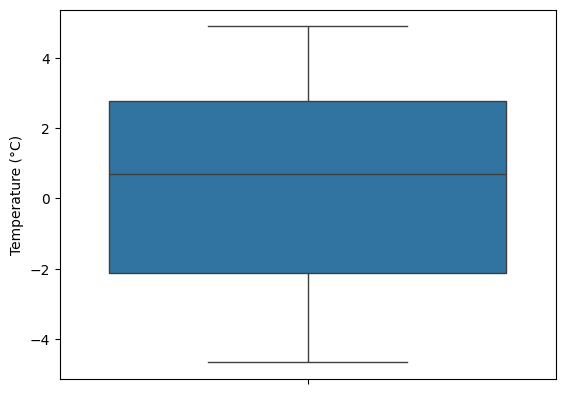

In [ ]:
#Outlier detection
sns.boxplot(df['Temperature (°C)'])

In [ ]:
x=df['Temperature (°C)']

In [ ]:
y=df['Ice Cream Sales (units)']

Text(0, 0.5, 'Ice Cream Sales (units)')

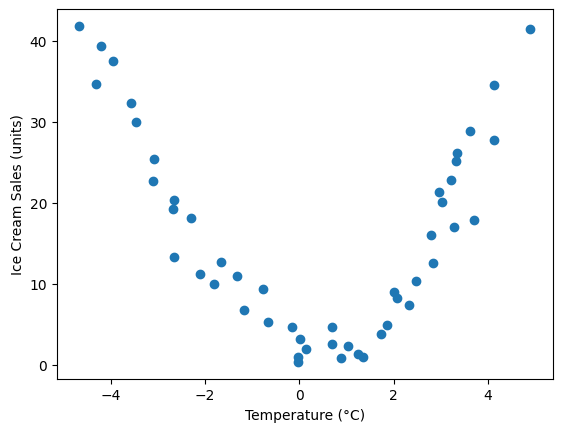

In [ ]:
plt.scatter(x,y)
plt.xlabel('Temperature (°C)')
plt.ylabel('Ice Cream Sales (units)')

In [ ]:
# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.15, random_state=123)

In [ ]:
print('First 5 rows of x_train:')
display(x_train.head())
print('\nFirst 5 rows of y_train:')
display(y_train.head())

First 5 rows of x_train:


,Temperature (°C)
29,1.359813
8,-2.672461
21,-0.033895
46,4.130868
11,-2.288264



First 5 rows of y_train:


,Ice Cream Sales (units)
29,0.953115
8,19.226970
21,0.897603
46,34.530743
11,18.123991


In [ ]:
print('First 5 rows of x_test:')
display(x_test.head())
print('\nFirst 5 rows of y_test:')
display(y_test.head())

First 5 rows of x_test:


,Temperature (°C)
10,-2.651498
13,-1.818938
30,1.740000
48,4.899032
18,-0.673753



First 5 rows of y_test:


,Ice Cream Sales (units)
10,13.275828
13,10.012868
30,3.782570
48,41.514822
18,5.210163


In [ ]:
print(f"number of instances for training:{len(x_train)}")
print(f"number of instances for testing:{len(x_test)}")

number of instances for training:41
number of instances for testing:8


In [ ]:
poly_features=PolynomialFeatures(degree=2)

In [ ]:
x_poly=poly_features.fit_transform(x.to_frame())

In [ ]:
lr_model=LinearRegression()
lr_model.fit(x_poly,y)

LinearRegression()

In [ ]:
model = LinearRegression()
x_train_poly = poly_features.transform(x_train.to_frame())
model.fit(x_train_poly, y_train)
print("Model Trained Successfully")

Model Trained Successfully


In [ ]:
y_pred=lr_model.predict(x_poly)
df=pd.DataFrame({'Actual':y,'Predicted':y_pred})
print(df)

       Actual  Predicted
0   41.842986  46.564507
1   34.661120  40.600548
2   39.383001  38.915089
3   37.539845  34.749272
4   32.284531  29.331940
5   30.001138  27.649735
6   22.635401  23.192862
7   25.365022  22.863178
8   19.226970  18.222266
9   20.279679  18.009098
10  13.275828  18.000794
11  18.123991  14.418541
12  11.218294  12.853070
13  10.012868  10.504868
14  12.615181   9.364587
15  10.957731   7.264266
16   6.689123   6.437055
17   9.392969   4.683654
18   5.210163   4.337906
19   4.673643   3.116139
20   0.328626   2.983983
21   0.897603   2.981829
22   3.165600   2.944811
23   1.931416   2.869446
24   2.576782   3.251711
25   4.625689   3.259923
26   0.789974   3.630683
27   2.313806   4.026226
28   1.292361   4.744891
29   0.953115   5.213321
30   3.782570   7.055902
31   4.857988   7.690948
32   8.943823   8.616039
33   8.170735   9.118494
34   7.412094  10.874961
35  10.336631  12.092557
36  15.996620  14.843721
37  12.568237  15.287199
38  21.342916  16.539614


In [ ]:
# Evaluate model performance on training data using MAE, MSE, RMSE, and R2 score
y_train_pred = model.predict(x_train_poly)
mae = mean_absolute_error(y_train, y_train_pred)
mse = mean_squared_error(y_train, y_train_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_train, y_train_pred)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):",rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 2.587464204374009
Mean Squared Error (MSE): 9.828414811481867
Root MSE (RMSE): 3.1350302728174517
R2 Score: 0.9268179544044519


In [ ]:
# Evaluate model performance on testing data using MAE, MSE, RMSE, and R2 score
x_test_poly = poly_features.transform(x_test.to_frame())
y_test_pred = model.predict(x_test_poly)
mae = mean_absolute_error(y_test, y_test_pred)
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_test_pred)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root MSE (RMSE):", rmse)
print("R2 Score: ", r2)

Mean Absolute Error (MAE): 3.0466103501101225
Mean Squared Error (MSE): 13.077367609444007
Root MSE (RMSE): 3.6162643168667867
R2 Score:  0.9361541090570978


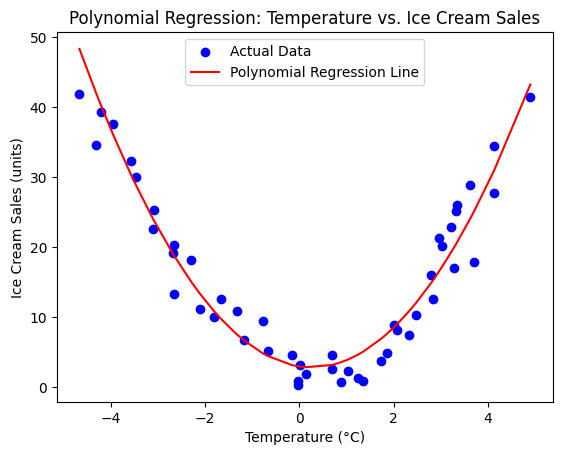

In [ ]:
plt.scatter(x, y, color='blue', label='Actual Data')
plt.plot(x, model.predict(poly_features.transform(x.to_frame())), color='red', label='Polynomial Regression Line')
plt.xlabel('Temperature (°C)')
plt.ylabel('Ice Cream Sales (units)')
plt.title('Polynomial Regression: Temperature vs. Ice Cream Sales')
plt.legend()
plt.show()